In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

# 1. spontaneous running

In [3]:
# neural_root = '/home/wx2203/Weihao/data_locker/step_2/'
prefix = '/mnt/staging/' # or 
# prefix = '/scratch/' #for s1n3/4

mouse = 'cm126'


step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'
face_h5_root = step_3_root+mouse+'/dlc_face_h5s/'
pupil_root = step_3_root

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"



In [5]:
# files without random stim
f2 = list(set(glob.glob(step_2_root+"*126/[1-3]/H_*[B-J]*.mat")) 
          - set(glob.glob(step_2_root+"*126/[2]/H_*[BCD]*.mat")))

file_spont = f2
file_spont

['/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/3/H_runF_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/1/H_runJ_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/2/H_runI_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/1/H_runC_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/1/H_runD_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/1/H_runG_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/2/H_runE_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/2/H_runJ_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/1/H_runB_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/3/H_runB_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_2/cm126/1/H_runE_stim_1.mat',
 '/mnt/sta

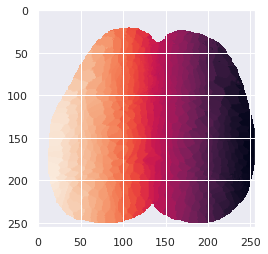

In [6]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [7]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

In [ ]:
sns.set_style("whitegrid", {'axes.grid' : False})
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

data_joint=pd.DataFrame()
big_df_concat = pd.DataFrame()

for i_file,fname in enumerate(file_spont): 
    
    ################################### identity 
    run_name = fname[-15:-4]
    day = fname.split(mouse)[1][1:2]
    mouse_day = mouse+'_'+day
    run = fname[-15:-11]
    session_name = mouse_day+'_'+run
    
    # load pupil 
    try:
        
        fhere = list(set(glob.glob(pupil_root+"*behavior.mat")))[0]
        f_b =  h5py.File(fhere,'r') 
        B=f_b['B']
        session=B[session_name]
        pupil_temp = np.squeeze(session['pupil'])[500:-505];pupil_temp[0]=0;pupil_temp[-1]=0
        pupil_pc = stats.zscore(np.array(pd.DataFrame(pupil_temp).interpolate()))

        rotf = stats.zscore(np.array(pd.DataFrame(np.squeeze(session['rotf'])[500:-505]).interpolate()))
        rot_raw = np.array(stats.zscore(rotf))
            
            
    except:
        print('pupil missing ',mouse_day+'_'+run)
        continue
    
    
    ################################### whisking velocity (11980,)
    try:
        f_name_dlc = glob.glob(face_h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        prominent_whiskers=bodyparts[7:] #plot most prominent whiskers

        vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(prominent_whiskers):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel_df[bpt] = vel
        mean_vel = vel_df.mean(axis=1)
        smooth_mean_vel = mean_vel.rolling(60).std()
        smooth_mean_vel_ds = np.mean(smooth_mean_vel[:-1].values.reshape((-1,3)),axis=1) #(11980,)
        whisk_vel = smooth_mean_vel_ds[500:-505]
        #
        nose_pts=bodyparts[:7]
        nose_vel_df = pd.DataFrame()
        for i_bpt,bpt in enumerate(nose_pts):
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            nose_vel_df[bpt] = vel
        mean_nose_vel = nose_vel_df.mean(axis=1)
        smooth_mean_nose_vel = mean_nose_vel.rolling(60).std() # smooth
        smooth_mean_nose_vel_ds = np.mean(smooth_mean_nose_vel[:-1].values.reshape((-1,3)),axis=1)
        nose_vel = smooth_mean_nose_vel_ds[500:-505]

    except:
        print('whisking velocity missing ',mouse_day+'_'+run)
        continue
        
    try:
        with(h5py.File(pjoin(step_3_root,mouse,
                             day,run+'_cam_pc.mat'),'r')) as f_b:
            motionS = f_b['motionS']# this is the HDF5 reference
            motion_pc = {key: [] for key in list(motionS.keys())} 
            for key in list(motionS.keys()):
                motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
                motion_pc[key]= motion_pc[key].iloc[:,:-5]
                
                motion_pc[key] = motion_pc[key].rolling(window=5,axis=1).std()
                motion_pc[key]=motion_pc[key].iloc[:,500:-500]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming

    except:
        
        continue

        
    # try:    
    f_config = h5py.File(step_0_root+mouse+'/groom_config_'+mouse+'.mat','r')

    x_top_left = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,0]
    x_botton_right = np.array(f_config[f_config['xx']['face'][int(day)-1,0]])[:,1]
    y_top_left = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,0]
    y_botton_right = np.array(f_config[f_config['yy']['face'][int(day)-1,0]])[:,1]

    out_h = int((x_botton_right - x_top_left)/3)
    out_w = int((y_botton_right - y_top_left)/3) 
    y = int(x_top_left/3)
    x = int(y_top_left/3)

    f_name_dlc = glob.glob(h5_root + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df = Dataframe[scorer] # de-level

    paws_vel_df = pd.DataFrame()
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
    for i_bpt,bpt in enumerate(bodyparts):

        p_value = new_df[bpt]['likelihood']
        new_df[bpt]['x'][p_value<0.1]=np.nan
        new_df[bpt]['y'][p_value<0.1]=np.nan
        new_df[bpt] = new_df[bpt].interpolate()
        new_df[bpt] = new_df[bpt].fillna(0) # in case nan in first few rows

        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
        vel = pd.DataFrame(vel).rolling(30).std()
        vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
        paws_vel_df[bpt] = vel[500:-505]
    LFP_vel = np.array(paws_vel_df['LFP'])
    RFP_vel = np.array(paws_vel_df['RFP'])


    fig,ax = plt.subplots(1)
    plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
    plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
    rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
    plt.ylim([0,400])
    plt.legend()
    ax.add_patch(rect)
    plt.gca().invert_yaxis()

    rise_LFP = new_df['LFP']['y'].copy().diff().rolling(5).std().rolling(3).mean()
    rise_LFP = np.mean(rise_LFP[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    rise_LFP = rise_LFP[500:-505] 
    # rise_LFP = normalize(stats.zscore(rise_LFP[500:-505]))

    rise_LFP_raw = new_df['LFP']['y'].copy().diff()
    rise_LFP_raw = np.mean(rise_LFP_raw[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    rise_LFP_raw = rise_LFP_raw[500:-505]   

    is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
    is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
    is_groom = np.logical_or(is_groom_LFP,is_groom_RFP)
    is_groom_smooth = is_groom.rolling(50).mean()

    is_groom_smooth_ds = np.mean(is_groom_smooth[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

    #downsample
    new_df = new_df[:-1].groupby(np.arange(new_df[:-1].shape[0])//3, axis=0).mean()
    df_cam0 = new_df.iloc[500:-505]


#     except:
#         print('grooming missing ',mouse_day+'_'+run)   
#         continue
        
    try:
        paws_vel_df = pd.DataFrame()
        f_name_dlc = glob.glob(mirror_h5_root + mouse_day[2:]+'_'+run+"*h5", recursive=True)[0] # target at specific run
        Dataframe = pd.read_hdf(f_name_dlc)
        scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
        new_df = Dataframe[scorer] # de-level
        #     bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()
        bodyparts=['LFP','RFP','LHP','RHP']
        for i_bpt,bpt in enumerate(bodyparts):
            p_value = new_df[bpt]['likelihood']
            new_df[bpt]['x'][p_value<0.1]=np.nan
            new_df[bpt]['y'][p_value<0.1]=np.nan
            new_df[bpt] = new_df[bpt].interpolate()
            new_df[bpt] = new_df[bpt].fillna(0) # nan appears in first few rows
            
            vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
            vel = pd.DataFrame(vel).rolling(60).mean()
            vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
            paws_vel_df[bpt] = vel[500:-505]
        mirrorLFP_vel = np.array(paws_vel_df['LFP'])
        mirrorRFP_vel = np.array(paws_vel_df['RFP'])
        mirrorLHP_vel = np.array(paws_vel_df['LHP'])
        mirrorRHP_vel = np.array(paws_vel_df['RHP'])
        #downsample
        new_df = new_df[:-1].groupby(np.arange(new_df[:-1].shape[0])//3, axis=0).mean()
        df_cam1 = new_df.iloc[500:-505]

    except:
        print('mirror paws velocity missing ',mouse_day+'_'+run)
        continue        
        
    
    face_pc = motion_pc['face'].iloc[:200,:].mean(axis=0)
    face_pc = stats.zscore(face_pc)
    body_pc = motion_pc['body'].iloc[:200,:].mean(axis=0)
    body_pc = stats.zscore(body_pc)    
    whisk_vel_norm = stats.zscore(whisk_vel)
    nose_vel_norm = stats.zscore(nose_vel)
    pupil_pc_norm = stats.zscore(pupil_pc)
    LFP_vel_norm = stats.zscore(LFP_vel)
    RFP_vel_norm = stats.zscore(RFP_vel)    
    mirrorLFP_vel_norm = stats.zscore(mirrorLFP_vel)
    mirrorRFP_vel_norm = stats.zscore(mirrorRFP_vel)
    mirrorLHP_vel_norm = stats.zscore(mirrorLHP_vel)
    mirrorRHP_vel_norm = stats.zscore(mirrorRHP_vel)
    data_pot = pd.concat([df_cam0,df_cam1],
                         keys=['cam0','cam1'],names=['column_level'],axis=1)
    

    
    big_df = pd.DataFrame()
    all_bev = ['face_pc','body_pc','whisk_vel_norm','nose_vel_norm',
              'pupil_pc_norm','LFP_vel_norm','RFP_vel_norm','mirrorLFP_vel_norm',
              'mirrorRFP_vel_norm','mirrorLHP_vel_norm','mirrorRHP_vel_norm',
              'rot_raw']
    for bev in all_bev:
        exec("big_df[bev] = normalize({})".format(bev))
    big_df['rise_LFP']=rise_LFP
    big_df['is_groom_smooth_ds']=is_groom_smooth_ds
    
    #behavior segmentation
    is_whisking = np.logical_and(np.logical_and(big_df['whisk_vel_norm']>0.3, 
                              big_df['LFP_vel_norm']<0.1),big_df['rot_raw']<0.2)
    is_reach = big_df['rise_LFP']>22
    
    is_running = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                              big_df['LFP_vel_norm']>0.2),big_df['rot_raw']>0.2),~is_reach)
    
    is_groom_paw = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.5, 
                              big_df['LFP_vel_norm']>0.2),big_df['rot_raw']<0.2),~is_reach)
    is_groom_lick = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']>0.5, 
                              big_df['LFP_vel_norm']<0.2),big_df['rot_raw']<0.2),~is_reach)     
    is_rest = np.logical_and(np.logical_and(np.logical_and(big_df['is_groom_smooth_ds']<0.1, 
                              big_df['LFP_vel_norm']<0.1),big_df['rot_raw']<0.2),big_df['whisk_vel_norm']<0.1)
    
    moseq_list = ['is_rest','is_whisking','is_reach','is_running','is_groom_paw','is_groom_lick']
    for moseq in moseq_list:
        exec("big_df[moseq] = {}".format(moseq))
        
    tmp = pd.concat([big_df], keys=[mouse_day+'_'+run], names=['row_level'])
    big_df_concat = big_df_concat.append(tmp)


    plt.figure(figsize=(18,8.5))
    plt.plot(normalize(whisk_vel_norm)+6,label='whisk vel') 
    plt.plot(normalize(mirrorLHP_vel_norm)+5,label='mirrorLFP vel')                           
    plt.plot(normalize(RFP_vel_norm)+4,label='RFP vel')            
    plt.plot(normalize(LFP_vel_norm)+3,label='LFP vel')
    plt.plot(normalize(rot_raw)+2,label='rotary')
    # plt.plot(normalize(face_pc)+1,label='face-pc')
    plt.plot(normalize(body_pc)+1,label='body-pc')
    plt.plot(is_groom_smooth_ds,label='is groom?')
    plt.plot(normalize(rise_LFP_raw)-1,label='rise LFP in y')
    
    col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
    col_list_palette = sns.xkcd_palette(col_list)
    
    # moseq
    for i, moseq in enumerate(moseq_list):
        plt.vlines(np.where(big_df[moseq]==True), -1.5-i*0.4, -1.9-i*0.4,linewidth=0.1,color=col_list_palette[i])
        plt.vlines(0, 8, 9,linewidth=10,color=col_list_palette[i],label='moseq '+moseq[3:])#for the legend

    plt.ylim([-4,7.2])
    plt.title(mouse_day+'_'+run_name)
    plt.legend(bbox_to_anchor=(1.04,0.5), loc="center left", borderaxespad=0,fontsize = 13)

    

pupil missing  cm126_3_runF
pupil missing  cm126_2_runE
pupil missing  cm126_3_runE
pupil missing  cm126_3_runG
pupil missing  cm126_3_runD
pupil missing  cm126_1_runI
pupil missing  cm126_2_runH


In [11]:
# save_root = str(PREPARES / "behavior-segment") + "/"
save_root = str(PREPARES / "behavior-segment") + "/"

save_pickle(big_df_concat,save_root+'big_df_concat_'+mouse)

In [10]:
big_df_concat

face_pc   body_pc  whisk_vel_norm  nose_vel_norm  \
row_level                                                               
cm126_1_runJ 0      0.104470  0.017096        0.007411       0.131439   
             1      0.122479  0.010767        0.008015       0.130992   
             2      0.154300  0.011785        0.008184       0.131879   
             3      0.138547  0.012660        0.008223       0.132688   
             4      0.130102  0.012200        0.007686       0.131883   
...                      ...       ...             ...            ...   
cm126_3_runC 10970  0.229453  0.080146        0.020333       0.017492   
             10971  0.255439  0.079608        0.020097       0.017516   
             10972  0.251714  0.084019        0.019228       0.017417   
             10973  0.239947  0.090271        0.018820       0.016776   
             10974  0.231691  0.082149        0.018708       0.016849   

                    pupil_pc_norm  LFP_vel_norm  RFP_vel_norm  \
row_level                                                       
cm126_1_runJ 0           0.000000      0.006362      0.008762   
             1           0.000346      0.006458      0.008497   
             2           0.000692      0.007115      0.007350   
             3           0.001038      0.007058      0.007232   
             4           0.001385      0.006946      0.006989   
...                           ...           ...           ...   
cm126_3_runC 10970       0.885315      0.010963      0.013049   
             10971       0.904519      0.010564      0.012590   
             10972       0.907839      0.011121      0.012826   
             10973       0.873063      0.011171      0.013134   
             10974       0.000000      0.011604      0.012369   

                    mirrorLFP_vel_norm  mirrorRFP_vel_norm  \
row_level                                                    
cm126_1_runJ 0                0.001667            0.001433   
             1                0.001672            0.001273   
             2                0.001644            0.001336   
             3                0.001670            0.001398   
             4                0.001763            0.001051   
...                                ...                 ...   
cm126_3_runC 10970            0.008639            0.002073   
             10971            0.008743            0.002253   
             10972            0.008747            0.002289   
             10973            0.008912            0.002305   
             10974            0.009109            0.002366   

                    mirrorLHP_vel_norm  mirrorRHP_vel_norm   rot_raw  \
row_level                                                              
cm126_1_runJ 0                0.003303            0.011384  0.005416   
             1                0.003620            0.010800  0.005078   
             2                0.003519            0.010737  0.005078   
             3                0.003988            0.011195  0.005078   
             4                0.003330            0.011960  0.005416   
...                                ...                 ...       ...   
cm126_3_runC 10970            0.002846            0.003987  0.123136   
             10971            0.002844            0.004095  0.122749   
             10972            0.002915            0.003650  0.120620   
             10973            0.002942            0.003600  0.119071   
             10974            0.003337            0.003446  0.116747   

                    rise_LFP  is_groom_smooth_ds  is_rest  is_whisking  \
row_level                                                                
cm126_1_runJ 0      0.050086                 0.0     True        False   
             1      0.050137                 0.0     True        False   
             2      0.122646                 0.0     True        False   
             3      0.151019                 0.0     True        False   
             4      0.051213         